### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DAFM = data.copy()
DAFM = DAFM[['date', 'price']]
DAFM['date'] = pd.to_datetime(DAFM['date'])
mask = (DAFM['date']>=obv_st_date) & (DAFM['date']<=obv_end_date)
DAFM = DAFM.loc[mask]
DAFM = DAFM.set_index('date')
DAFM.head()

,price
date,
2008-01-15,400.00
2008-01-15,3636.36
2008-01-15,3636.36
2008-01-15,242.42
2008-01-15,969.70


In [13]:
DAFM = DAFM.resample('MS').mean()
DAFM.head()

,price
date,
2008-01-01,1056.864390
2008-02-01,1136.594375
2008-03-01,1091.044937
2008-04-01,1011.162530
2008-05-01,1011.921319


In [14]:
price = DAFM['price']
date = DAFM.index

##### Normalized the data

In [15]:
scaler = MinMaxScaler()

In [16]:
DAFM = scaler.fit_transform(DAFM)
DAFM = pd.DataFrame(DAFM)
DAFM.head()

,0
0,0.197472
1,0.242857
2,0.216929
3,0.171456
4,0.171888


In [17]:
DAFM['date']=date
DAFM = DAFM.set_index('date')
DAFM.columns=['price']
DAFM.head()

,price
date,
2008-01-01,0.197472
2008-02-01,0.242857
2008-03-01,0.216929
2008-04-01,0.171456
2008-05-01,0.171888


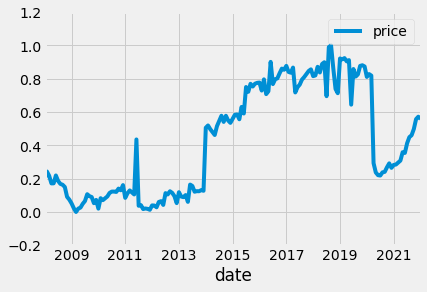

In [18]:
DAFM.plot(grid=True)
plt.show()

Nearly Positive Trend

In [19]:
DAFM_diff = DAFM.diff(1).dropna()
DAFM_diff.head()

,price
date,
2008-02-01,0.045385
2008-03-01,-0.025929
2008-04-01,-0.045472
2008-05-01,0.000432
2008-06-01,0.047272


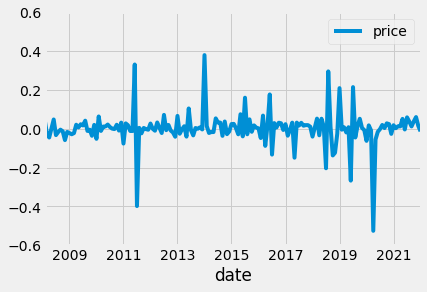

In [20]:
DAFM_diff.plot(grid=True)
plt.show()

##### Checking Random Walk

In [21]:
RW_DAFM = adfuller(DAFM_diff['price'])
RW_DAFM[1] # print P-value. If p-value<5%, reject null hypothesis

3.2537466973232263e-29

##### Plotting ACF and PACF

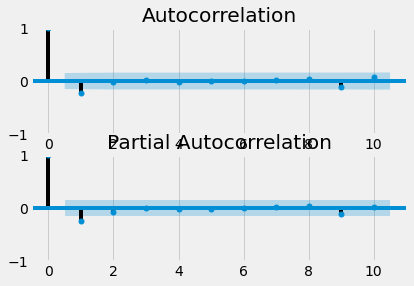

In [22]:
fig, axes=plt.subplots(2,1)
plot_acf(DAFM_diff, lags=10, ax=axes[0])
plot_pacf(DAFM_diff, lags=10, ax=axes[1])
plt.show()

##### Choose smallest AIC and BIC

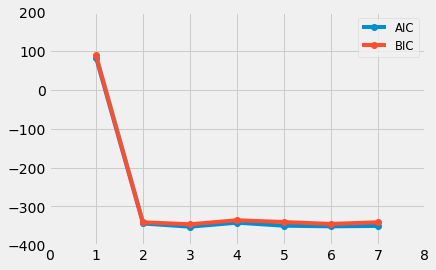

In [23]:
AIC, BIC = AIC_BIC_withOrderRange(DAFM, p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [24]:
AIC, BIC

(array([ 269.3579257 ,   82.61105543, -343.92847895, -352.13483277,
        -341.8565007 , -349.5456111 , -351.22998843, -350.15336195]),
 array([ 272.48782441,   88.87085286, -340.80451497, -345.88690481,
        -335.59670327, -340.15591496, -344.98206047, -340.78147001]))

##### We will run again 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [25]:
mod_orders = [
    (0,1,0), 
    (0,1,1), 
    (1,0,0), 
    (1,0,1), 
    (1,1,0), 
    (1,1,1)
]

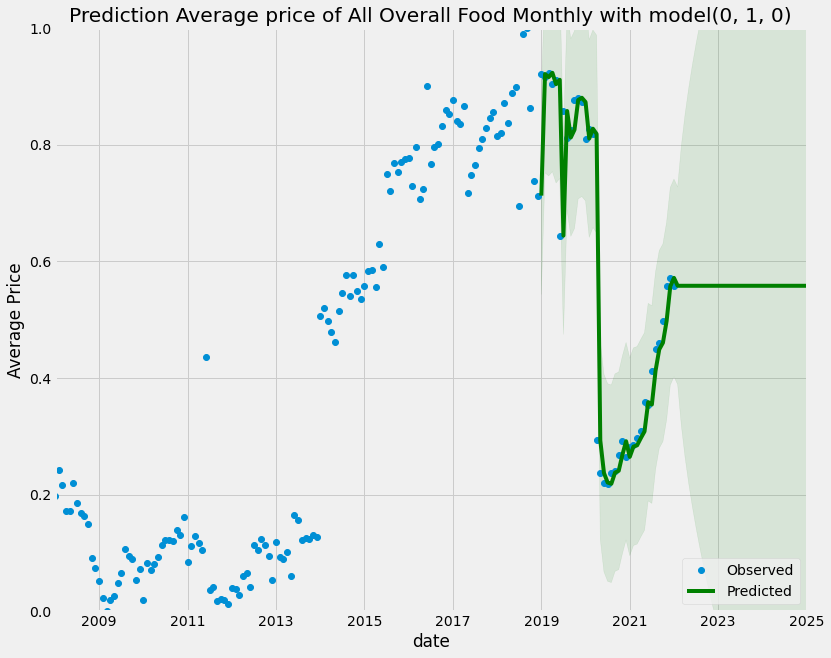

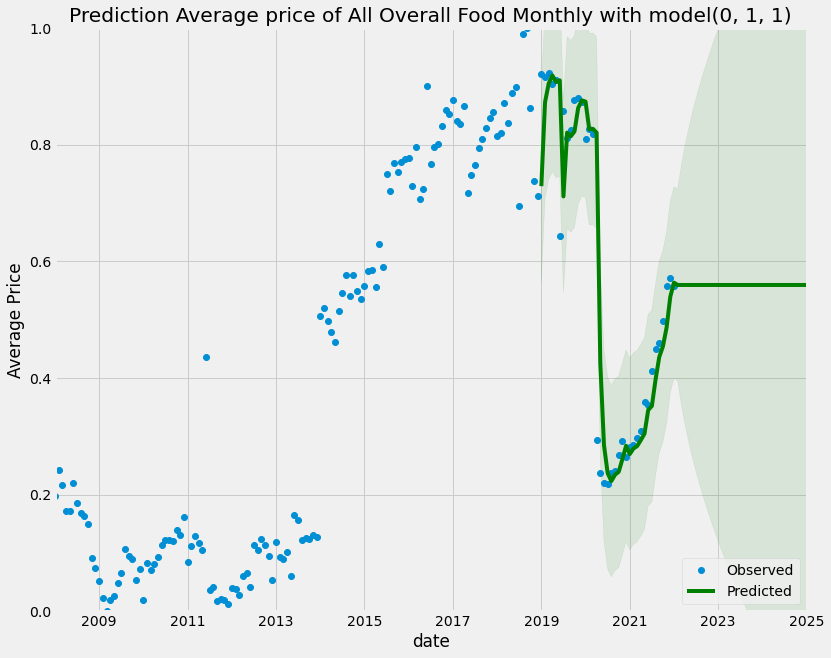

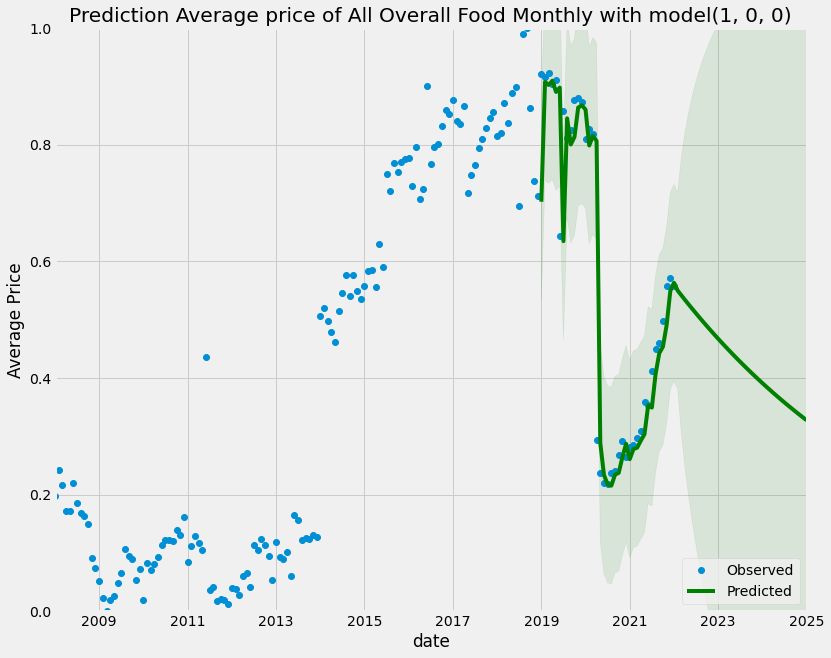

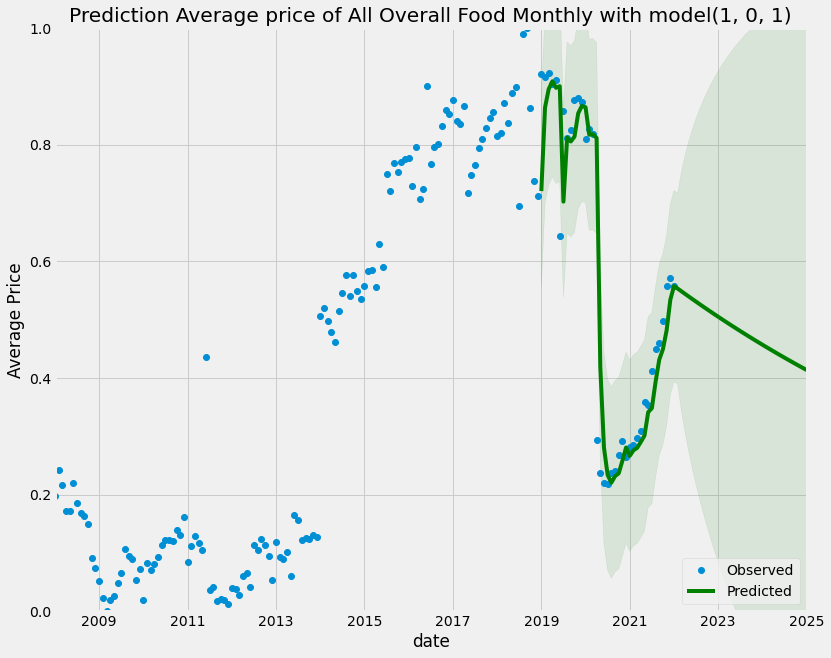

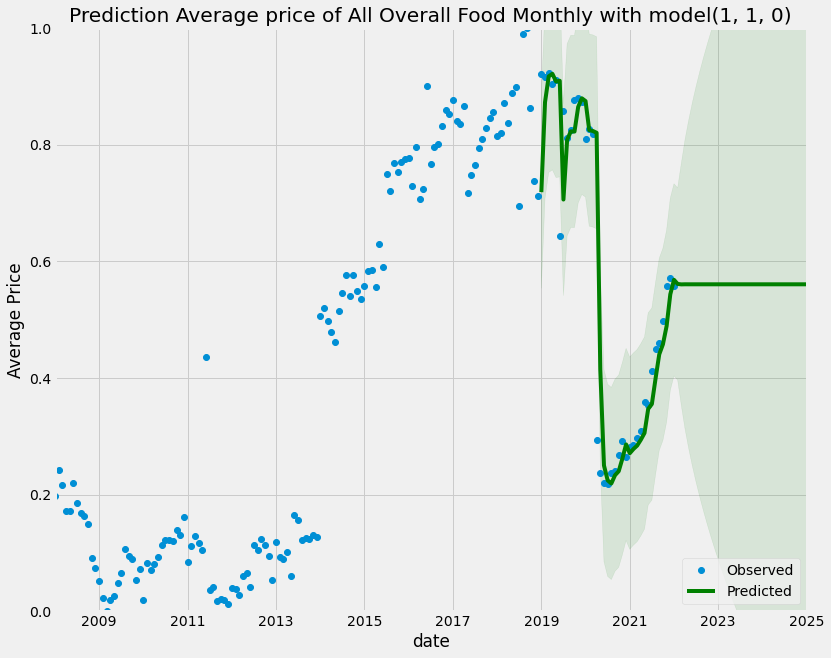

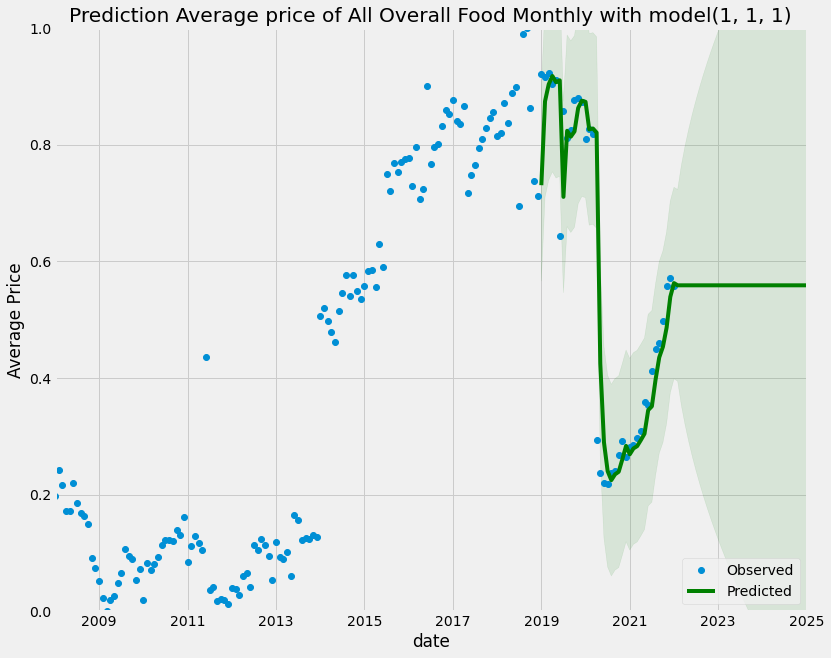

In [26]:
DAFM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DAFM, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of All Overall Food Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DAFM_models.append(model)

Now we choose (1, 0, 0)

In [27]:
DAFM_model = DAFM_models[2]

In [28]:
DAFM_pred_normalized = DAFM_model.predict(pred_st_date, pred_end_date)
DAFM_pred_normalized

2019-01-01    0.702275
2019-02-01    0.907666
2019-03-01    0.902506
2019-04-01    0.909751
2019-05-01    0.890609
                ...   
2024-09-01    0.347536
2024-10-01    0.342429
2024-11-01    0.337396
2024-12-01    0.332438
2025-01-01    0.327552
Freq: MS, Name: predicted_mean, Length: 73, dtype: float64

In [29]:
pred_date = DAFM_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2019-01-01', '2019-02-01', '2019-03-01', '2019-04-01',
               '2019-05-01', '2019-06-01', '2019-07-01', '2019-08-01',
               '2019-09-01', '2019-10-01', '2019-11-01', '2019-12-01',
               '2020-01-01', '2020-02-01', '2020-03-01', '2020-04-01',
               '2020-05-01', '2020-06-01', '2020-07-01', '2020-08-01',
               '2020-09-01', '2020-10-01', '2020-11-01', '2020-12-01',
               '2021-01-01', '2021-02-01', '2021-03-01', '2021-04-01',
               '2021-05-01', '2021-06-01', '2021-07-01', '2021-08-01',
               '2021-09-01', '2021-10-01', '2021-11-01', '2021-12-01',
               '2022-01-01', '2022-02-01', '2022-03-01', '2022-04-01',
               '2022-05-01', '2022-06-01', '2022-07-01', '2022-08-01',
               '2022-09-01', '2022-10-01', '2022-11-01', '2022-12-01',
               '2023-01-01', '2023-02-01', '2023-03-01', '2023-04-01',
               '2023-05-01', '2023-06-01', '2023-07-01', '2023-08-01',
      

In [30]:
DAFM_pred_normalized_df = pd.DataFrame(DAFM_pred_normalized)
DAFM_pred_normalized_df = DAFM_pred_normalized_df[:-1] # the last index doesn't need
DAFM_pred_normalized_df

,predicted_mean
2019-01-01,0.702275
2019-02-01,0.907666
2019-03-01,0.902506
2019-04-01,0.909751
2019-05-01,0.890609
...,...
2024-08-01,0.352720
2024-09-01,0.347536
2024-10-01,0.342429
2024-11-01,0.337396


We need to un-normalized the predicted value to get actual price

In [31]:
DAFM_pred_act = scaler.inverse_transform(DAFM_pred_normalized_df)
DAFM_pred_act_df = pd.DataFrame(DAFM_pred_act)
DAFM_pred_act_df['date'] = pred_date
DAFM_pred_act_df.columns = ['Predicted Price', 'date']
DAFM_pred_act_df.set_index('date')

,Predicted Price
date,
2019-01-01,1943.666822
2019-02-01,2304.484103
2019-03-01,2295.418918
2019-04-01,2308.147229
2019-05-01,2274.518702
...,...
2024-08-01,1329.592695
2024-09-01,1320.486533
2024-10-01,1311.514196
